# Matrix Multiplication Benchmark: C++ vs Rust vs Go

C++, Rust, and Go are widely used compiled programming languages, each offering different approaches to performance optimization, memory management, and runtime execution. C++ provides fine-grained control over hardware resources, Rust emphasizes memory safety and efficient resource management without a garbage collector, while Go prioritizes simplicity and concurrency through its runtime environment.

The objective of this experiment is to **compare the computational performance of C++, Rust, and Go using dense matrix multiplication as a common benchmark**. Matrix multiplication is a fundamental operation in scientific computing, High-Performance Computing (HPC), and Artificial Intelligence (AI), making it a useful workload for investigating execution efficiency across programming languages.

To ensure a meaningful comparison, all three implementations use the same sequential matrix multiplication algorithm, equivalent data structures, and comparable compiler optimization settings. The experiment focuses on single-threaded execution, without explicit parallelism or external numerical libraries such as BLAS.

## 1. Install compilers using `apt-get`

Requires sudo privileges and network access. If running as root (for example in some containers), remove `sudo`. The commands install **g++ (C++), rustc and cargo (Rust), and golang-go (Go)**.

In [12]:
!sudo apt-get install -y build-essential rustc cargo golang-go

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
build-essential is already the newest version (12.10ubuntu1).
rustc is already the newest version (1.75.0+dfsg0ubuntu1-0ubuntu7.4).
cargo is already the newest version (1.75.0+dfsg0ubuntu1-0ubuntu7.4).
golang-go is already the newest version (2:1.22~2build1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [13]:
import shutil, subprocess
for executable in ("g++", "rustc", "go"):
    location = shutil.which(executable)
    print(f"{executable}: {location or 'NOT INSTALLED'}")
    if location:
        command = {"g++": ["g++", "--version"], "rustc": ["rustc", "--version"], "go": ["go", "version"]}[executable]
        print(subprocess.check_output(command, text=True).splitlines()[0])

g++: /usr/bin/g++
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
rustc: /usr/bin/rustc
rustc 1.75.0 (82e1608df 2023-12-21) (built from a source tarball)
go: /usr/bin/go
go version go1.22.2 linux/amd64


## 2. Benchmark design

All programs use row-major `float64` matrices, deterministic input values, and the **i–k–j** loop ordering:

$$C_{ij} = \sum_{k=0}^{N-1} A_{ik}B_{kj} $$

- `A[i,k] = ((i+k) % 7) + 1`
- `B[k,j] = ((k+j) % 5) + 1`
- `C` is initially zero.
- Each program outputs elapsed seconds and the sum of the entries of `C`.

The same algorithm is used in each language; compiler optimization and runtime details can still differ.

In [14]:
from pathlib import Path
import subprocess, statistics, math
import pandas as pd
import matplotlib.pyplot as plt

WORK = Path("matrix_benchmark")
WORK.mkdir(exist_ok=True)
print("Working directory:", WORK.resolve())

Working directory: /content/matrix_benchmark


## 3. C++

In [15]:
cpp = r'''
#include <iostream>
#include <vector>
#include <chrono>
#include <iomanip>
#include <cstdlib>

int main(int argc, char** argv)
{
    if (argc != 2)
      return 1;

    const size_t n = std::stoull(argv[1]);

    std::vector<double> A(n*n), B(n*n), C(n*n, 0.0);

    for (size_t i=0; i<n; ++i)
        for (size_t j=0; j<n; ++j)
        {
            A[i*n+j] = double((i+j)%7+1);
            B[i*n+j] = double((i+j)%5+1);
        }

    auto start = std::chrono::steady_clock::now();

    for (size_t i=0; i<n; ++i)
        for (size_t k=0; k<n; ++k)
        {
            double a = A[i*n+k];
            for (size_t j=0; j<n; ++j) C[i*n+j] += a*B[k*n+j];
        }

    auto stop = std::chrono::steady_clock::now();

    double checksum=0;

    for (double v: C)
       checksum += v;

         std::cout << std::setprecision(17) << std::chrono::duration<double>(stop-start).count() << " " << checksum << "\n";
}

'''
(WORK / "mm.cpp").write_text(cpp)
print("Saved:", WORK / "mm.cpp")

Saved: matrix_benchmark/mm.cpp


## 4. Rust

In [16]:
rust = r'''
use std::env;
use std::time::Instant;

fn main()
{
    let n: usize = env::args().nth(1).expect("matrix size").parse().expect("integer size");
    let mut a = vec![0.0_f64; n*n];
    let mut b = vec![0.0_f64; n*n];
    let mut c = vec![0.0_f64; n*n];

    for i in 0..n
    {
        for j in 0..n
        {
            a[i*n+j] = ((i+j)%7+1) as f64;
            b[i*n+j] = ((i+j)%5+1) as f64;
        }
    }

    let start = Instant::now();

    for i in 0..n
    {
        for k in 0..n
        {
            let aik = a[i*n+k];

            for j in 0..n
            {
              c[i*n+j] += aik*b[k*n+j];
            }
        }
    }

    let elapsed = start.elapsed().as_secs_f64();
    let checksum: f64 = c.iter().sum();

    println!("{:.17} {:.17}", elapsed, checksum);
}
'''
(WORK / "mm.rs").write_text(rust)
print("Saved:", WORK / "mm.rs")

Saved: matrix_benchmark/mm.rs


## 5. Go

In [21]:
go = r'''package main
import (
    "fmt"
    "os"
    "strconv"
    "time"
)
func main() {
    if len(os.Args) != 2 { panic("matrix size required") }
    n, err := strconv.Atoi(os.Args[1]); if err != nil { panic(err) }
    a := make([]float64, n*n)
    b := make([]float64, n*n)
    c := make([]float64, n*n)
    for i:=0; i<n; i++ {
        for j:=0; j<n; j++ {
            a[i*n+j] = float64((i+j)%7+1)
            b[i*n+j] = float64((i+j)%5+1)
        }
    }
    start := time.Now()
    for i:=0; i<n; i++ {
        for k:=0; k<n; k++ {
            aik := a[i*n+k]
            for j:=0; j<n; j++ { c[i*n+j] += aik*b[k*n+j] }
        }
    }
    elapsed := time.Since(start).Seconds()
    checksum := 0.0
    for _, v := range c { checksum += v }
    fmt.Printf("%.17f %.17f\n", elapsed, checksum)
}
'''
(WORK / "mm.go").write_text(go)
print("Saved:", WORK / "mm.go")

Saved: matrix_benchmark/mm.go


## 6. Compile optimized executables

- **C++:** `g++ -O3 -std=c++17`
- **Rust:** `rustc -C opt-level=3`
- **Go:** `go build` (standard optimized build)

The flags are not exactly equivalent across toolchains. Record compiler versions when reporting results.

In [22]:
builds = [
    ["g++", "-O3", "-std=c++17", str(WORK/"mm.cpp"), "-o", str(WORK/"mm_cpp")],
    ["rustc", "-C", "opt-level=3", str(WORK/"mm.rs"), "-o", str(WORK/"mm_rust")],
    ["go", "build", "-o", str(WORK/"mm_go"), str(WORK/"mm.go")],
]
for command in builds:
    print("Building:", " ".join(command))
    subprocess.run(command, check=True)
print("All executables compiled successfully.")

Building: g++ -O3 -std=c++17 matrix_benchmark/mm.cpp -o matrix_benchmark/mm_cpp
Building: rustc -C opt-level=3 matrix_benchmark/mm.rs -o matrix_benchmark/mm_rust
Building: go build -o matrix_benchmark/mm_go matrix_benchmark/mm.go
All executables compiled successfully.


## 7. Validate and benchmark

A separate mathematical identity checks the checksum:

$$\sum_{i,j} C_{ij} = \sum_k \left(\sum_i A_{ik}\right)\left(\sum_j B_{kj}\right)$$

Each executable is warmed up once per matrix size, then timed **five times**. We report the median. Approximate floating-point work is `2N³` operations. Results depend on hardware, CPU frequency, thermal conditions, compiler versions, and system load.

In [23]:

def expected_checksum(n):
    return float(sum(
        sum((i+k)%7+1 for i in range(n)) *
        sum((k+j)%5+1 for j in range(n))
        for k in range(n)
    ))

def run_one(executable, n):
    output = subprocess.check_output(
        [str(executable.resolve()), str(n)],
        text=True
    ).strip()

    seconds, checksum = map(float, output.split())
    assert seconds > 0
    assert math.isclose(
        checksum, expected_checksum(n),
        rel_tol=1e-10, abs_tol=1e-7
    ), (executable, n, checksum)

    return seconds

SIZES = [128, 256, 512]
REPEATS = 5

programs = {
    "C++": WORK/"mm_cpp",
    "Rust": WORK/"mm_rust",
    "Go": WORK/"mm_go"
}

records = []

for n in SIZES:
    for language, executable in programs.items():
        run_one(executable, n)  # Warm-up

        samples = [
            run_one(executable, n)
            for _ in range(REPEATS)
        ]

        records.append({
            "Matrix Size": n,
            "Language": language,
            "Execution Time (s)": statistics.median(samples)
        })

# Create DataFrame
results = pd.DataFrame(records)

# Pivot table: one column per language
execution_times = results.pivot(
    index="Matrix Size",
    columns="Language",
    values="Execution Time (s)"
)

# Reorder columns and format results
execution_times = execution_times[["C++", "Rust", "Go"]]

execution_times.columns.name = None

display(execution_times.round(5))


,C++,Rust,Go
Matrix Size,,,
128,0.00088,0.00166,0.00543
256,0.00707,0.01275,0.02643
512,0.05890,0.08585,0.19051


## 8. Compare execution times, throughput, and speedup

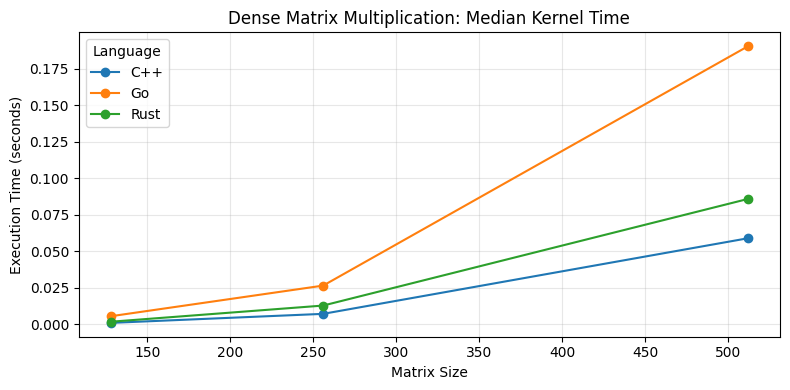

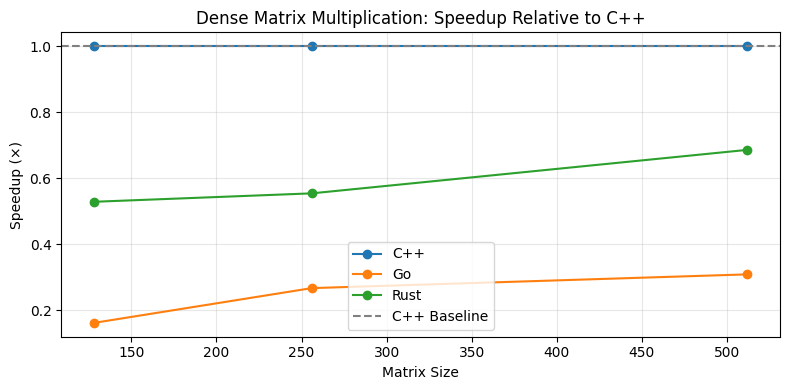

In [26]:
# Execution Time
times = results.pivot(
    index="Matrix Size",
    columns="Language",
    values="Execution Time (s)"
)

ax = times.plot(
    marker="o",
    figsize=(8, 4),
    title="Dense Matrix Multiplication: Median Kernel Time"
)
ax.set_xlabel(
    "Matrix Size"
)
ax.set_ylabel(
    "Execution Time (seconds)"
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Speedup Relative to C++
speedup = times.rdiv(times["C++"], axis=0)

ax = speedup.plot(
    marker="o",
    figsize=(8, 4),
    title="Dense Matrix Multiplication: Speedup Relative to C++"
)
ax.axhline(
    y=1.0,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="C++ Baseline"
)
ax.set_xlabel(
    "Matrix Size"
)
ax.set_ylabel(
    "Speedup (\u00d7)"
)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()